# Demo: Will this vulnerability be rated Critical?

**CS383 · Capstone deployment demo.** This notebook walks the capstone workflow end to end on a real dataset, from question to a saved model that `app.py` serves as a live Streamlit app.

**Data:** NVD CVE API 2.0 (National Vulnerability Database, NIST). Pulled with `pull_nvd.py`.
*This product uses data from the NVD API but is not endorsed or certified by the NVD.*

Run `python pull_nvd.py` once in this folder first. It creates `nvd_cves.csv`.

## 1. Define the problem

**Question.** When a vulnerability is first published, can we predict whether it will be rated **Critical** (CVSS v3 score 9.0 or higher) from what we know about it, such as its weakness type (CWE), the vendor, the kind of product, and who reported it?

- **Type:** binary classification. **Target:** `is_critical` = 1 if the CVSS v3 severity is `CRITICAL`, else 0.
- **Candidate features, and why each might matter:**
    - `cwe_primary` (weakness type): it says *how* the bug works, and some kinds (injection, code execution) are plausibly worse than others (information leaks).
    - `vendor` and `cpe_part` (application / OS / hardware): some vendors and product types have a track record of serious flaws.
    - `source` (who reported it): different reporting organizations describe and score issues differently.
    - `pub_year` and `n_references`: severity ratings might drift over time, and a CVE that draws attention might collect more links.
  Step 5 shows how I decide which of these to keep.
- **Deliberately NOT features:** the CVSS metrics (`base_score`, `attack_vector`, `privileges_required`, ...). The severity rating is *computed from* those metrics, so using them would hand the model the answer. Step 7 shows how big that leak is.

**Why it matters.** A security team facing hundreds of new CVEs a week wants to know which to look at first.

## 2. Collect data

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
raw = pd.read_csv("nvd_cves.csv")
print(raw.shape)
raw.head()

(68769, 20)


,cve_id,published,source,vuln_status,n_references,cwe_primary,cwe_all,vendor,cpe_part,cvss_version,base_score,base_severity,attack_vector,attack_complexity,privileges_required,user_interaction,scope,confidentiality,integrity,availability
0,CVE-2023-0028,2023-01-01T01:15:12.627,security@huntr.dev,Modified,4,CWE-79,CWE-79,linagora,a,3.1,5.4,MEDIUM,NETWORK,LOW,LOW,REQUIRED,CHANGED,LOW,LOW,NONE
1,CVE-2021-41823,2023-01-01T06:15:09.283,cve@mitre.org,Modified,2,CWE-79,CWE-79,kemptechnologies,a,3.1,6.1,MEDIUM,NETWORK,LOW,NONE,REQUIRED,CHANGED,LOW,LOW,NONE
2,CVE-2022-47952,2023-01-01T06:15:09.860,cve@mitre.org,Modified,10,CWE-203,CWE-203,linuxcontainers,a,3.1,3.3,LOW,LOCAL,LOW,LOW,NONE,UNCHANGED,LOW,NONE,NONE
3,CVE-2022-48198,2023-01-01T07:15:10.187,cve@mitre.org,Modified,6,CWE-668,CWE-668,ntpd_driver_project,a,3.1,9.8,CRITICAL,NETWORK,LOW,NONE,NONE,UNCHANGED,HIGH,HIGH,HIGH
4,CVE-2022-34322,2023-01-01T08:15:10.007,cve@mitre.org,Modified,2,CWE-79,CWE-79,sage,a,3.1,9.0,CRITICAL,NETWORK,LOW,LOW,REQUIRED,CHANGED,HIGH,HIGH,HIGH


**Source:** [NVD CVE API 2.0](https://nvd.nist.gov/developers/vulnerabilities). **Provenance.** The NVD is run by NIST. Each row is one CVE record: an identifier for a publicly disclosed vulnerability, enriched by NVD analysts with a CVSS score, weakness type (CWE), and affected products (CPE). `pull_nvd.py` flattens the nested JSON from the API into one row per CVE and skips records with status *Rejected*.

In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68769 entries, 0 to 68768
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   cve_id               68769 non-null  object 
 1   published            68769 non-null  object 
 2   source               68769 non-null  object 
 3   vuln_status          68769 non-null  object 
 4   n_references         68769 non-null  int64  
 5   cwe_primary          67975 non-null  object 
 6   cwe_all              67975 non-null  object 
 7   vendor               61007 non-null  object 
 8   cpe_part             61007 non-null  object 
 9   cvss_version         68444 non-null  float64
 10  base_score           68444 non-null  float64
 11  base_severity        68444 non-null  object 
 12  attack_vector        68444 non-null  object 
 13  attack_complexity    68444 non-null  object 
 14  privileges_required  68444 non-null  object 
 15  user_interaction     68444 non-null 

## 3. Clean the data

Real data has issues. Three here, each handled and explained.

In [3]:
df = raw.copy()

# Issue 1: duplicate CVE IDs (a resumed pull can re-read a window)
print("duplicate cve_id rows:", df.duplicated("cve_id").sum())
df = df.drop_duplicates("cve_id")

# Issue 2: no CVSS v3 rating -> no target. A few CVEs are not scored yet, and CVEs from before 2016
# only have v2 (which has no 'Critical' level).
print("rows with no v3 severity:", df["base_severity"].isna().sum(), "of", len(df))
df = df.dropna(subset=["base_severity"]).copy()

# Issue 3: missing categorical values. Blank vendor = NVD has no product list for the CVE yet.
for col in ["cwe_primary", "vendor", "cpe_part", "source"]:
    print(f"{col}: {df[col].isna().sum()} missing")
    df[col] = df[col].fillna("unknown")

df["pub_year"] = pd.to_datetime(df["published"]).dt.year
df["is_critical"] = (df["base_severity"] == "CRITICAL").astype(int)
print(df.shape)

duplicate cve_id rows: 0
rows with no v3 severity: 325 of 68769
cwe_primary: 787 missing
vendor: 7438 missing
cpe_part: 7438 missing
source: 0 missing
(68444, 22)


1. **Duplicates** were dropped (keep one row per CVE).
2. **No v3 rating** means no label, so those rows are dropped. It is a small share of this 2023–2024 data (see the count above), but the model still only describes CVEs that *were* scored under v3.
3. **Missing categories** were filled with the label `unknown` instead of dropped, because "NVD has no product data yet" is itself information.

## 4. Explore the data

base_severity
MEDIUM      32328
HIGH        25321
CRITICAL     9566
LOW          1228
NONE            1
Name: count, dtype: int64

Critical share: 14.0%
distinct weakness types: 493 | distinct vendors: 8952


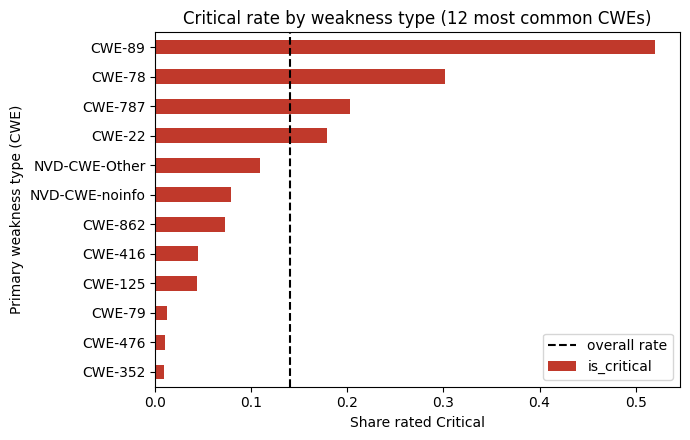

In [4]:
print(df["base_severity"].value_counts())
print(f"\nCritical share: {df['is_critical'].mean():.1%}")
print("distinct weakness types:", df["cwe_primary"].nunique(), "| distinct vendors:", df["vendor"].nunique())

top = df["cwe_primary"].value_counts().head(12).index
rate = df[df["cwe_primary"].isin(top)].groupby("cwe_primary")["is_critical"].mean().sort_values()
ax = rate.plot.barh(figsize=(7, 4.5), color="#c0392b")
ax.axvline(df["is_critical"].mean(), color="black", ls="--", label="overall rate")
ax.set_xlabel("Share rated Critical")
ax.set_ylabel("Primary weakness type (CWE)")
ax.set_title("Critical rate by weakness type (12 most common CWEs)")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows and how it affects choices.** Critical is a minority class, so plain accuracy will look good even for a model that never predicts Critical. We will judge models with **F1 and ROC AUC** and compare against a baseline. The Critical rate usually differs a lot across weakness types (compare injection or file-upload flaws with cross-site scripting in your chart), so `cwe_primary` should carry real signal. `vendor` has thousands of values, so the encoder will group rare ones together.

## 5. Build a model

This step covers the split, **choosing the features**, and the baseline and first models.

Split **first**. Choosing features is a modeling decision too, so I make it using the **training set only**. If I peeked at the test set while choosing, the final test score would be optimistic.

In [5]:
ALL_CAT = ["cwe_primary", "vendor", "cpe_part", "source"]
ALL_NUM = ["pub_year", "n_references"]
y = df["is_critical"]
X_train_all, X_test_all, y_train, y_test = train_test_split(
    df[ALL_CAT + ALL_NUM], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train_all.shape, X_test_all.shape, f"critical share train {y_train.mean():.1%} / test {y_test.mean():.1%}")


def make_pipeline(model, cat, num=()):
    # min_frequency groups rare vendors/CWEs into one 'infrequent' bucket; unseen values at predict time
    # (a brand-new vendor in the app) go to that bucket instead of crashing.
    # Numeric columns are scaled: otherwise a column like n_references next to thousands of 0/1 columns
    # makes logistic regression's optimizer converge very slowly.
    steps = []
    if cat:
        steps.append(("cat", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist"), list(cat)))
    if num:
        steps.append(("num", StandardScaler(), list(num)))
    return Pipeline([("prep", ColumnTransformer(steps)), ("model", model)])

(54755, 6) (13689, 6) critical share train 14.0% / test 14.0%


### How I pick features: four questions, in this order

1. **Would I know it at prediction time?** If not, it is leakage, however helpful it looks.
2. **Is it usable?** How much is missing, and how many distinct values does it have?
3. **Does it carry signal on its own?** Score a model that sees only that feature.
4. **Does it still help when everything else is already in the model?** Remove it and see what is lost. A feature can look useful alone but add nothing because another feature already says the same thing.

Questions 1 and 2 can be answered by thinking and counting. Questions 3 and 4 need cross-validation, run on the training set.

**Question 1: availability.** I start from every column and cross some off before measuring anything.

In [6]:
pd.set_option("display.max_colwidth", None)
candidates = pd.DataFrame([
    ("cve_id",                         "yes",    "drop",  "An identifier: unique in every row, so there is nothing to learn."),
    ("vuln_status",                    "no",     "drop",  "Set during NVD processing. It describes the paperwork, not the vulnerability."),
    ("base_score and the CVSS metrics", "no",    "drop",  "Severity is computed from them. Step 7 shows the leak."),
    ("cwe_all",                        "yes",    "drop",  "Mostly repeats cwe_primary. Keep one."),
    ("cwe_primary",                    "yes",    "test",  "Weakness type."),
    ("vendor",                         "yes",    "test",  "Who makes the product."),
    ("cpe_part",                       "yes",    "test",  "Application, operating system, or hardware."),
    ("source",                         "yes",    "test",  "Which organization reported it."),
    ("pub_year",                       "yes",    "test",  "Year published."),
    ("n_references",                   "partly", "test",  "The link list can keep growing after publication."),
], columns=["column", "known at prediction time?", "first decision", "why"])
candidates

,column,known at prediction time?,first decision,why
0,cve_id,yes,drop,"An identifier: unique in every row, so there is nothing to learn."
1,vuln_status,no,drop,"Set during NVD processing. It describes the paperwork, not the vulnerability."
2,base_score and the CVSS metrics,no,drop,Severity is computed from them. Step 7 shows the leak.
3,cwe_all,yes,drop,Mostly repeats cwe_primary. Keep one.
4,cwe_primary,yes,test,Weakness type.
5,vendor,yes,test,Who makes the product.
6,cpe_part,yes,test,"Application, operating system, or hardware."
7,source,yes,test,Which organization reported it.
8,pub_year,yes,test,Year published.
9,n_references,partly,test,The link list can keep growing after publication.


**Question 2: usability.**

In [7]:
rows = []
for c in ALL_CAT:
    rows.append((c, (X_train_all[c] == "unknown").mean(), X_train_all[c].nunique()))
for c in ALL_NUM:
    rows.append((c, 0.0, X_train_all[c].nunique()))
pd.DataFrame(rows, columns=["feature", "share unknown", "distinct values"]).set_index("feature").round(3)

,share unknown,distinct values
feature,,
cwe_primary,0.011,463
vendor,0.110,7918
cpe_part,0.110,4
source,0.000,316
pub_year,0.000,2
n_references,0.000,64


`vendor` has thousands of values and is unknown for roughly one CVE in ten, so the encoder will group the rare ones. `pub_year` has only **two** values, so a model cannot learn a trend from it, and in a deployed app any future year would be outside everything it has seen. Neither is disqualifying yet, so they go on to the measured tests.

**Question 3: signal on its own.** Each feature goes into its own small model. ROC AUC of 0.5 is a coin flip.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alone = {}
with warnings.catch_warnings():
    # On some Macs numpy prints harmless floating-point RuntimeWarnings for these tiny one-column fits.
    warnings.simplefilter("ignore", RuntimeWarning)
    for f in ALL_CAT + ALL_NUM:
        pipe = make_pipeline(LogisticRegression(max_iter=2000),
                             cat=[f] if f in ALL_CAT else [], num=[f] if f in ALL_NUM else [])
        alone[f] = cross_val_score(pipe, X_train_all, y_train, cv=cv, scoring="roc_auc").mean()
pd.Series(alone, name="AUC alone").sort_values(ascending=False).round(3)

cwe_primary     0.823
source          0.750
vendor          0.719
pub_year        0.539
cpe_part        0.528
n_references    0.467
Name: AUC alone, dtype: float64

Weakness type is the strongest on its own, with vendor and source in the middle. The product type, the year, and the reference count sit close to 0.5, so they tell us little by themselves.

**Question 4: does it still help when the others are present?** Remove one feature at a time, from a quick random forest, and look at the cost. I also need to know how much the score moves by chance, so I measure the **fold-to-fold noise**: the standard deviation of the five cross-validation AUCs. A change smaller than that is not a real difference.

In [9]:
def quick_rf():
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=RANDOM_STATE)

def cv_auc(cat, num):
    return cross_val_score(make_pipeline(quick_rf(), cat=cat, num=num), X_train_all, y_train, cv=cv, scoring="roc_auc")

all_scores = cv_auc(ALL_CAT, ALL_NUM)
noise = all_scores.std()
aucs = {"all six features": all_scores.mean()}
for f in ALL_CAT + ALL_NUM:
    aucs[f"without {f}"] = cv_auc([c for c in ALL_CAT if c != f], [n for n in ALL_NUM if n != f]).mean()
drop_one = pd.DataFrame({"AUC": aucs})
drop_one["change vs. all six"] = drop_one["AUC"] - all_scores.mean()
print(f"fold-to-fold noise (std of the 5 AUCs): {noise:.4f}")
drop_one.round(4)

fold-to-fold noise (std of the 5 AUCs): 0.0028


,AUC,change vs. all six
all six features,0.8759,0.0000
without cwe_primary,0.7852,-0.0907
without vendor,0.8696,-0.0063
without cpe_part,0.8755,-0.0004
without source,0.8657,-0.0102
without pub_year,0.8750,-0.0009
without n_references,0.8744,-0.0015


**Decision rule.** If removing a feature costs less than the noise, it is not earning its place, and the simpler model wins: fewer inputs to collect, fewer things to break in the app. Applying that to the table: weakness type is worth far more than anything else, and `source` and `vendor` each cost more than the noise when removed. `cpe_part`, `pub_year` and `n_references` each cost less than the noise, so they go. `pub_year` and `n_references` also had the extra problems we saw (two values only; a list that grows after publication), which would have been reasons to be careful even if they had helped a little.

This is a rule of thumb, not a law, and it is based on one dataset and one random split, so I check the reduced model against the full one.

In [10]:
CAT = ["cwe_primary", "vendor", "source"]     # decision from the tables above
NUM = []
FEATURES = CAT + NUM
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]

reduced = cv_auc(CAT, NUM)
print(f"{len(FEATURES)} features: AUC {reduced.mean():.4f}   all six: AUC {all_scores.mean():.4f}   (noise +/- {noise:.4f})")

models = {
    "Baseline (most frequent)": make_pipeline(DummyClassifier(strategy="most_frequent"), cat=CAT, num=NUM),
    "Logistic regression": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"), cat=CAT, num=NUM),
    "Random forest": make_pipeline(RandomForestClassifier(
        n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE), cat=CAT, num=NUM),
}

3 features: AUC 0.8724   all six: AUC 0.8759   (noise +/- 0.0028)


The three-feature model scores within about one noise-width of the six-feature one, so I keep the simpler model and build the baseline and two real models on it.

## 6. Evaluate the model

Models are compared with **5-fold cross-validation on the training set**. The test set stays locked: it is opened exactly once, at the end of Step 7, for the model I commit to.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = {}
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    rows[name] = {k: s[f"test_{k}"].mean() for k in ["accuracy", "f1", "roc_auc"]}
results = pd.DataFrame(rows).T.round(3)
results

,accuracy,f1,roc_auc
Baseline (most frequent),0.860,0.000,0.500
Logistic regression,0.767,0.496,0.866
Random forest,0.780,0.505,0.873


**What the numbers mean here.** The baseline shows why accuracy alone misleads: predicting "not Critical" every time scores high accuracy but an F1 of 0 and an AUC of 0.5. For a security team, two questions matter. *Of the CVEs the model flags, how many really are Critical?* (precision) and *Of the real Criticals, how many does it catch?* (recall). F1 balances the two. AUC says how well the model ranks CVEs from least to most likely Critical, whatever cutoff is used. A real model has to beat the baseline on **F1 and AUC**.

In [12]:
best_name = results.drop(index="Baseline (most frequent)")["f1"].idxmax()
print("Best initial model by cross-validated F1:", best_name)

Best initial model by cross-validated F1: Random forest


## 7. Improve the model

**Attempt: tune the random forest.** Three settings: `min_samples_leaf` (how small a leaf may get; 1 lets a tree memorize individual rows), `max_features` (how many columns each split considers), and `min_frequency` (how rare a vendor or CWE can be before it is lumped into one "infrequent" group). All tuning uses cross-validation on the **training set**. (The grid search below takes a minute or two.)

In [13]:
param_grid = {
    "model__min_samples_leaf": [1, 3, 10],
    "model__max_features": ["sqrt", 0.1],
    "prep__cat__min_frequency": [5, 20],
}
search = GridSearchCV(
    make_pipeline(RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=RANDOM_STATE), cat=CAT, num=NUM),
    param_grid, cv=cv, scoring="f1")
search.fit(X_train, y_train)

grid_table = pd.DataFrame(search.cv_results_)[
    ["param_model__min_samples_leaf", "param_model__max_features", "param_prep__cat__min_frequency", "mean_test_score"]]
grid_table.columns = ["min_samples_leaf", "max_features", "min_frequency", "CV F1"]
print("Best settings:", search.best_params_)
grid_table.sort_values("CV F1", ascending=False).head(5).round(4)

Best settings: {'model__max_features': 0.1, 'model__min_samples_leaf': 1, 'prep__cat__min_frequency': 5}


,min_samples_leaf,max_features,min_frequency,CV F1
6,1,0.1,5,0.5361
0,1,sqrt,5,0.5325
8,3,0.1,5,0.5209
7,1,0.1,20,0.5175
1,1,sqrt,20,0.5158


In [14]:
# Refit the best settings with the same 200 trees as the initial model, so the comparison is fair.
tuned = clone(models["Random forest"]).set_params(**search.best_params_)
s = cross_validate(tuned, X_train, y_train, cv=cv, scoring=["f1", "roc_auc"])
print(f"Initial random forest: CV F1 {results.loc['Random forest', 'f1']:.3f}   AUC {results.loc['Random forest', 'roc_auc']:.3f}")
print(f"Tuned random forest:   CV F1 {s['test_f1'].mean():.3f}   AUC {s['test_roc_auc'].mean():.3f}")

Initial random forest: CV F1 0.505   AUC 0.873
Tuned random forest:   CV F1 0.537   AUC 0.855


Tuning raised the cross-validated F1, and the winning settings are the *least* restrictive ones (leaves of size 1, rare vendors kept separate). That is a warning sign, not a victory. Many CVEs are published in batches: the same vendor, the same weakness type, the same reporter, often with the same severity. In random cross-validation a row's near-twin is usually in the training folds, so a model that **memorizes combinations** scores better than it will on a vendor or a year it has not seen.

**Check:** train on the earlier year only and score on the later year, using the training set only. This is a closer match to real use, where the model faces CVEs it has never seen.

In [15]:
combo = X_train.astype(str).agg("|".join, axis=1)
print(f"{combo.nunique():,} distinct (weakness, vendor, source) combinations in {len(combo):,} training rows")

year = pd.to_datetime(df.loc[X_train.index, "published"]).dt.year
early, late = (year == year.min()), (year == year.max())

def forward_check(pipe):
    p = clone(pipe).fit(X_train[early], y_train[early])
    return (f1_score(y_train[late], p.predict(X_train[late])),
            roc_auc_score(y_train[late], p.predict_proba(X_train[late])[:, 1]))

candidates_final = {"Baseline (most frequent)": models["Baseline (most frequent)"],
                    "Initial model": models[best_name], "Tuned random forest": tuned}
rows = {}
for name, pipe in candidates_final.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "roc_auc"])
    f_fwd, a_fwd = forward_check(pipe)
    rows[name] = {"CV F1 (random)": s["test_f1"].mean(), "CV AUC (random)": s["test_roc_auc"].mean(),
                  f"F1 {year.min()} to {year.max()}": f_fwd, f"AUC {year.min()} to {year.max()}": a_fwd}
improvement = pd.DataFrame(rows).T.round(3)
improvement

21,714 distinct (weakness, vendor, source) combinations in 54,755 training rows


,CV F1 (random),CV AUC (random),F1 2023 to 2024,AUC 2023 to 2024
Baseline (most frequent),0.000,0.500,0.000,0.500
Initial model,0.505,0.873,0.449,0.838
Tuned random forest,0.537,0.855,0.452,0.800


**Result.** Compare the two kinds of columns. The tuned model wins on F1 under random cross-validation, but when it must predict a *later* year its F1 is no better, and its AUC (how well it ranks CVEs) is lower in every column. Most of the "improvement" was memorizing repeated combinations, which does not carry over to new CVEs. So I **keep the simpler initial model**. This is a documented attempt that did not hold up, which is a legitimate outcome. The forward-in-time columns are also a more honest guide to how the model would perform on tomorrow's CVEs: lower than the random cross-validation numbers.

What I would try next: a time-based split for *all* model choices, or more informative features (for example, the text of the CVE description).

### Possible data leakage, and how I prevented it

- **The test set never influenced a choice.** I split first; the features were chosen (Step 5) and the settings tuned (above) using cross-validation on the training set only.
- **Preprocessing is inside the `Pipeline`.** The encoder is fitted on training folds only, never on held-out rows.
- **Target-derived columns are excluded.** The CVSS metrics are the clearest case, shown next.
- **Batch effects.** Near-duplicate CVEs across folds inflated the tuned model's score, which is why I added the forward-in-time check.

**The CVSS leak.** Severity is *computed from* the CVSS metrics, so a model that sees them can "predict" it almost perfectly. That looks like a great result and is useless, because the metrics exist only *after* someone has already rated the vulnerability.

In [16]:
leaky = ["base_score", "attack_vector", "attack_complexity", "privileges_required",
         "user_interaction", "scope", "confidentiality", "integrity", "availability"]
df_leaky = df.copy()
for c in leaky[1:]:
    df_leaky[c] = df_leaky[c].fillna("unknown")
Xl = df_leaky[FEATURES + leaky]
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    Xl, df_leaky["is_critical"], test_size=0.2, stratify=df_leaky["is_critical"], random_state=RANDOM_STATE)

leaky_pipe = make_pipeline(
    RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    cat=CAT + leaky[1:], num=NUM + ["base_score"])
s = cross_validate(leaky_pipe, Xl_train, yl_train, cv=cv, scoring=["f1", "roc_auc"])
print(f"With CVSS metrics:    F1 {s['test_f1'].mean():.3f}   AUC {s['test_roc_auc'].mean():.3f}   <- too good to be true")
print(f"Honest model:         F1 {results.loc[best_name, 'f1']:.3f}   AUC {results.loc[best_name, 'roc_auc']:.3f}")

With CVSS metrics:    F1 0.999   AUC 1.000   <- too good to be true
Honest model:         F1 0.505   AUC 0.873


When a score jumps from decent to near perfect, ask what the model can see that it would not have at prediction time. The honest number is the lower one.

### Final evaluation on the test set (once)

The decision is made, so the test set is opened now. All three models are scored on it a single time, and nothing is changed afterward.

In [17]:
test_rows = {}
for name, pipe in candidates_final.items():
    p = clone(pipe).fit(X_train, y_train)
    test_rows[name] = {"Test F1": f1_score(y_test, p.predict(X_test)),
                       "Test AUC": roc_auc_score(y_test, p.predict_proba(X_test)[:, 1])}
final_table = improvement.join(pd.DataFrame(test_rows).T).round(3)
final_table

,CV F1 (random),CV AUC (random),F1 2023 to 2024,AUC 2023 to 2024,Test F1,Test AUC
Baseline (most frequent),0.000,0.500,0.000,0.500,0.000,0.500
Initial model,0.505,0.873,0.449,0.838,0.521,0.884
Tuned random forest,0.537,0.855,0.452,0.800,0.560,0.861


**Reading the table.** The tuned model also scores a higher F1 on the test set. That does not change the decision, for two reasons. First, the choice was made *before* the test set was opened, and switching after seeing the test score would turn the test set into one more tuning tool. Second, the test set is a random sample from the same batches of CVEs, so it shares the near-twin effect that inflated the tuned model's cross-validated score. The forward-in-time columns are the fairer guide, and the tuned model's AUC is lower in every column, test set included.

              precision    recall  f1-score   support

not critical       0.96      0.78      0.86     11776
    critical       0.38      0.82      0.52      1913

    accuracy                           0.79     13689
   macro avg       0.67      0.80      0.69     13689
weighted avg       0.88      0.79      0.82     13689



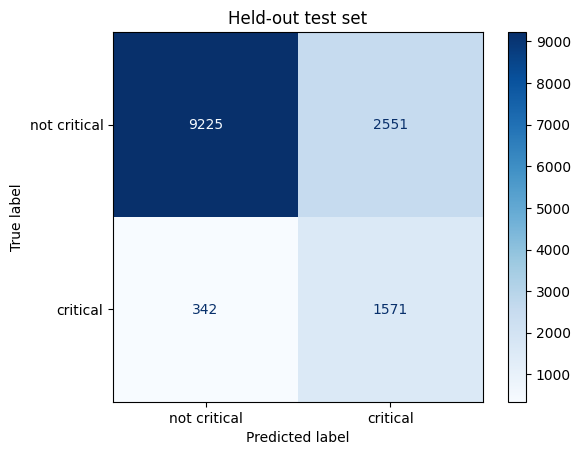

In [18]:
final = clone(models[best_name]).fit(X_train, y_train)     # the model I committed to: the initial one
pred = final.predict(X_test)
print(classification_report(y_test, pred, target_names=["not critical", "critical"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["not critical", "critical"], cmap="Blues")
plt.title("Held-out test set")
plt.show()

The test F1 should be close to the cross-validated F1. A big gap would mean the model had been tuned to the training data.

## 8. Communicate the findings

In [19]:
r = classification_report(y_test, pred, output_dict=True)["1"]
print(f"Of every 100 CVEs the model flags as Critical, about {r['precision'] * 100:.0f} really are.")
print(f"Of every 100 CVEs that really are Critical, it flags about {r['recall'] * 100:.0f}.")
print(f"For comparison, {df['is_critical'].mean() * 100:.0f} of every 100 CVEs are Critical to begin with.")

Of every 100 CVEs the model flags as Critical, about 38 really are.
Of every 100 CVEs that really are Critical, it flags about 82.
For comparison, 14 of every 100 CVEs are Critical to begin with.


**In plain language.** A new vulnerability is published, and before anyone has scored it, we ask whether it will turn out to be rated *Critical*. Using only the weakness type, the vendor, and who reported it, the model catches most real Criticals but also raises many false alarms. Its flags are right several times more often than picking CVEs at random, but most flags are still false alarms, so they are not reliable on their own.

**Does it answer the question?** Partly. Yes, those three facts do carry real signal about severity: the weakness type is by far the strongest. But they do not determine it. The details of *how* a bug can be exploited drive the real score, and we do not know them at prediction time.

**Predictive performance versus real-world usefulness.** The model is a triage aid: a way to decide which new CVEs a person should look at first. It is not a substitute for scoring. And the forward-in-time check in Step 7 shows its performance on genuinely new CVEs is lower than the headline cross-validation numbers.

**Correlation, not causation.** Nothing here says a vendor or a weakness type *causes* a high rating. The model finds patterns in how past CVEs were rated.

### Ethics and limitations

- **Who is represented?** The data covers CVEs that were scored under CVSS v3 and published in 2023 and 2024. A small number of vendors and reporting organizations account for many records, and the model has seen thousands of vendors only rarely. For a vendor it has barely seen, it falls back on weakness type and reporter alone, so it will be least reliable for small or new vendors, which are exactly the ones a security team may know least about. Ratings are also analysts' judgments, not measured facts.
- **Realistic worst case.** The model rates a truly Critical vulnerability as low risk and a team deprioritizes it, leaving a serious hole open longer. The opposite error, too many false alarms, wastes limited analyst time and can train people to ignore the tool.
- **What to verify before trusting it.** Test it on CVEs published *after* the training period, check accuracy separately for the largest vendors and for rare ones, compare its flags with what experienced analysts would prioritize, and check whether its probabilities are well calibrated (does "80%" mean about 80%?).

## Appendix A: Save the model for deployment

This is the separate deployment deliverable, not one of the eight steps. `app.py` needs two files from this notebook: the fitted pipeline, and a small JSON with the choices to show in the dropdowns. The pipeline contains the encoder, so the app passes in raw values and gets a prediction.

In [20]:
joblib.dump(final, "critical_model.joblib")

options = {
    "cwe_primary": df["cwe_primary"].value_counts().head(40).index.tolist(),
    "vendor": df["vendor"].value_counts().head(60).index.tolist(),
    "source": df["source"].value_counts().head(15).index.tolist(),
    "years": [int(df["pub_year"].min()), int(df["pub_year"].max())],
    "best_model": best_name,
    "test_f1": round(float((classification_report(y_test, pred, output_dict=True))["1"]["f1-score"]), 3),
    "critical_share": round(float(df["is_critical"].mean()), 3),
}
with open("app_options.json", "w") as fh:
    json.dump(options, fh, indent=2)

# Sanity check: reload the saved file and predict one made-up CVE, exactly as the app will.
reloaded = joblib.load("critical_model.joblib")
example = pd.DataFrame([{"cwe_primary": "CWE-89", "vendor": "wordpress", "source": options["source"][0]}])
print("P(critical) for the example:", round(float(reloaded.predict_proba(example)[0, 1]), 3))

import sklearn
print("scikit-learn", sklearn.__version__, "<- put this exact version in requirements.txt")

P(critical) for the example: 0.878
scikit-learn 1.7.2 <- put this exact version in requirements.txt


**Next:** run `streamlit run app.py` locally, then follow the deployment slides: push this folder to GitHub (including `critical_model.joblib` and `app_options.json`) and create the app on Streamlit Community Cloud.

## Appendix B: Use of generative AI

*An example of the disclosure the capstone asks for. Write yours in your own words.*

I chose the topic and the question, got my own NVD API key, and ran the data pull. I used Claude (Anthropic) to help with the initial drafts of the code and notebook. I then ran and tested everything myself, reviewed the results, and decided which features and model to keep.